# Import packages & Load functions and data

In [51]:
import os, glob, gzip
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
from matplotlib.ticker import FuncFormatter

In [56]:
def load_vcf( PATH_vcf, isGzip=True ):
    skiplines = 0 
    if isGzip == True: 
        open_func = gzip.open 
    else:
        open_func = open
    with open_func(PATH_vcf, 'rt') as vcf:
        for line in vcf:
            if line[:2] == '##':
                skiplines += 1
            else:
                break 
    vcf = pd.read_csv(PATH_vcf, sep='\t', skiprows=skiplines)
    return vcf

def append_INFO_entries(vcf, target_genes):
    ''' 
    Enrich VCF with parsed annotations from INFO field
    '''
    # Parse INFO fields once
    info_dicts = {
        tup.Identifier: parse_info_field(tup.INFO)
        for tup in vcf.itertuples()
    }
    
    # Extract dbSNP annotations
    for key, values in extract_dbsnp_annotations(vcf, info_dicts).items():
        vcf[key] = values
    
    # Extract SnpEff annotations
    for key, values in extract_snpeff_annotations(vcf, info_dicts, target_genes).items():
        vcf[key] = values
    
    return vcf

def parse_info_field(vcf_info_string):
    ''' 
    Parse VCF INFO field into dictionary
    '''
    return dict(
        entry.split('=', 1)
        for entry in vcf_info_string.split(';')
        if '=' in entry
    )

def extract_dbsnp_annotations(vcf, info_dicts):
    ''' 
    Extract dbSNP-related fields
    '''
    return {
        'ALLELEID': [info_dicts[id].get('ALLELEID', 'NotAvailable') for id in vcf.Identifier],
        'CLNSIG': [convert_CLNSIG_values(info_dicts[id].get('CLNSIG', 'NotAvailable'), 
                                         dbSNP_Number_to_CLNSIG) for id in vcf.Identifier],
        'CLNHGVS': [info_dicts[id].get('CLNHGVS', 'NotAvailable') for id in vcf.Identifier],
        'CLNVI': [info_dicts[id].get('CLNVI', 'NotAvailable') for id in vcf.Identifier],
        'RS': [info_dicts[id].get('RS', 'NotAvailable') for id in vcf.Identifier],
    }

def convert_CLNSIG_values( clnsig, dbSNP_Number_to_CLNSIG ):
    ''' 
    description: Given CLNSIG annotation value (from dbSNP VCF), convert the dbSNP CLNSIG numerical values to actual interpretable CLNSIG values.
    input: CLNSIG value obtained from SnpSift annotation using dbSNP VCF (string) and numeric-to-string CLNSIG mapper (dictionary)
    output: interpretable CLNSIG value (string)
    '''
    dict_clnsig = dict()
    for e1 in clnsig.split(','):
        for e2 in e1.split('|'):
            try: dict_clnsig[int(e2)] = dbSNP_Number_to_CLNSIG[e2]
            except: pass
    dict_clnsig = dict(sorted(dict_clnsig.items(), key=lambda x : x[0], reverse=True))
    if len(dict_clnsig)==0: return 'NotAvailable'
    for k, v in dict_clnsig.items():
        return v
    
def extract_snpeff_annotations(vcf, info_dicts, target_genes):
    ''' 
    Extract SnpEff ANN field annotations
    '''
    target_gene_set = set(target_genes['gene'])
    
    annotations = {
        'VarType': [], 'GeneName': [], 'VarImpact': [],
        'MANE': [], 'AaChange': [], 'LOF': []
    }
    
    for identifier in vcf.Identifier:
        ann = info_dicts[identifier].get('ANN', 'NotAvailable')
        
        if ann == 'NotAvailable':
            for key in annotations:
                annotations[key].append('NotAvailable')
            continue
        
        var_types, gene_names, impacts, mane, aa_changes = set(), set(), set(), set(), set()
        
        for entry in ann.split(','):
            fields = entry.split('|')
            if len(fields) < 11:  # ANN should have at least 11 fields
                continue
            
            var_types.add(fields[1])
            impacts.add(fields[2])
            mane.add(fields[6])
            if fields[3] in target_gene_set:
                gene_names.add(fields[3])
            if fields[10]:
                aa_changes.add(fields[10])
        
        annotations['VarType'].append(','.join(var_types))
        annotations['GeneName'].append(','.join(gene_names))
        annotations['VarImpact'].append(','.join(impacts))
        annotations['MANE'].append(','.join(mane))
        annotations['AaChange'].append(','.join(aa_changes))
        annotations['LOF'].append(info_dicts[identifier].get('LOF', 'NotAvailable'))
    
    return annotations
    
dbSNP_Number_to_CLNSIG = {
    '0' : 'Uncertain significance',
    '1' : 'Not provided',
    '2' : 'Benign',
    '3' : 'Likely benign',
    '4' : 'Likely pathogenic',
    '5' : 'Pathogenic',
    '6' : 'Drug response',

    '8' : 'Confers sensitivity',
    '9' : 'Risk factor', 
    '10' : 'Association',
    '11' : 'Protective',

    '12' : 'Conflicting interpretations of pathogenicity',
    '13' : 'Affects',
    '14' : 'Association not found',
    '15' : 'Benign/Likely benign',
    '16' : 'Pathogenic/Likely pathogenic',
    '17' : 'Conflicting data from submitters',
    '18' : 'Pathogenic, low penetrance',
    '19' : 'Likely pathogenic, low penetrance',
    '20' : 'Established risk allele',

    '21' : 'Likely risk allele',
    '22' : 'Uncertain risk allele',

    '225' : 'other',
    
    'NotAvailable' : 'NotAvailable',
}

# Select SVs with potential functional impacts
potential_deleterious_VarTypes = [
    'bidirectional_gene_fusion',
    'chromosome_number_variation',
    'conservative_inframe_deletion',
    'conservative_inframe_insertion',
    'disruptive_inframe_deletion',
    'disruptive_inframe_insertion',
    'duplication',
    'exon_loss_variant',
    'feature_ablation',
    'feature_fusion',
    'frameshift_variant',
    'gene_fusion',
    'inversion',
    'missense_variant',
    'splice_acceptor_variant',
    'splice_donor_variant',
    'splice_region_variant',
    'start_lost',
    'stop_gained',
    'stop_lost',
    'transcript_ablation',
]

def exons_from_gtf(gtf_path, transcript_id, chrom=None):
    """Pull {'Exon N': (start, end)} for one transcript from a (gzipped) Ensembl/GENCODE GTF."""
    opener = gzip.open if str(gtf_path).endswith(".gz") else open
    exons = {}
    with opener(gtf_path, "rt") as fh:
        for line in fh:
            if line.startswith("#"):
                continue
            f = line.rstrip("\n").split("\t")
            if len(f) < 9 or f[2] != "exon" or transcript_id not in f[8]:
                continue
            if chrom and f[0].lstrip("chr") != str(chrom).lstrip("chr"):
                continue
            num = f[8].split('exon_number "')[1].split('"')[0]
            exons[f"Exon {num}"] = (int(f[3]), int(f[4]))
    return exons


def plot_gene_tracks(intervals, exons=None, min_draw_bp=8, sort_by_start=False,
                     x_pad=150, bar_color=None, flip_to_transcript=False, dpi=500,
                     show_x_ticks=True, n_xticks=5, x_tick_round=None,
                     hollow_bars=False, savefig=None):
    """intervals: list of (label, start, end). exons: {'Exon N': (start, end)} or None.

    Text-free version: no exon labels, no bp annotations, no patient labels,
    no title, no axis label, no tick numbers — all text goes in via PowerPoint.
    Row order, top to bottom, follows `intervals`
    (or start-coordinate order if sort_by_start=True).
    flip_to_transcript=True -> 5'->3' of the transcript (for minus-strand genes).
    hollow_bars=True -> outlined, unfilled bars (deletions);
    False -> solid bars (insertions/duplications, matches the FLT3 figure).
    """
    exons = exons or {}
    if bar_color is None:
        bar_color = sns.color_palette("crest", 10)[7]
    rows = sorted(intervals, key=lambda t: (t[1], t[2])) if sort_by_start else list(intervals)
    n = len(rows)

    # Window covers every exon in `exons` AND every interval (same as the
    # FLT3 figure). If you don't want an exon shown, leave it out of the dict.
    xmin = min([s for _, s, _ in rows] + [s for s, _ in exons.values()]) - x_pad
    xmax = max([e for _, _, e in rows] + [e for _, e in exons.values()]) + x_pad

    fig, ax = plt.subplots(figsize=(12, 0.24 * n + 1.8), dpi=dpi)
    gene_y, exon_h = n + 1.4, 0.9
    bar_h = 0.45   # height of hollow bars (data units); ~ visual weight of the lw=9 solid bar

    # gene model track (no exon labels)
    ax.hlines(gene_y, xmin, xmax, color="black", lw=1.2, linestyle=(0, (4, 3)), zorder=1)
    for name, (s, e) in exons.items():
        ax.add_patch(FancyBboxPatch(
            (s, gene_y - exon_h / 2), e - s, exon_h,
            boxstyle="round,pad=0,rounding_size=6", mutation_aspect=0.02,
            facecolor="white", edgecolor="black", lw=1.2, zorder=3))
        # ax.axvspan(s, e, ymin=0, ymax=(n + 0.4) / (n + 2.4),
        #            color="0.55", alpha=0.10, lw=0, zorder=0)

    # SV bars, one row per interval (no length annotations)
    for i, (label, s, e) in enumerate(rows):
        y = n - 1 - i
        ds, de = s, e
        if (e - s + 1) < min_draw_bp:  # tiny events get a minimum visual width
            mid = (s + e) / 2
            ds, de = mid - min_draw_bp / 2, mid + min_draw_bp / 2
        if hollow_bars:   # outlined, unfilled -> deletion
            ax.add_patch(FancyBboxPatch(
                (ds, y - bar_h / 2), de - ds, bar_h,
                boxstyle="round,pad=0,rounding_size=6", mutation_aspect=0.02,
                facecolor="none", edgecolor=bar_color, lw=1.2, zorder=3))
        else:             # solid -> insertion/duplication (matches FLT3)
            ax.plot([ds, de], [y, y], color=bar_color, lw=9,
                    solid_capstyle="round", zorder=3)

    # no text anywhere: no patient labels, no axis title, no tick numbers
    ax.set_yticks([])
    ax.set_ylim(-0.8, n + 2.4)
    ax.set_xlim(xmin, xmax)
    if flip_to_transcript:
        ax.invert_xaxis()

    if show_x_ticks:
        ticks = np.linspace(xmin, xmax, n_xticks)   # exactly n_xticks, evenly spaced
        if x_tick_round:                            # optional: snap to clean coordinates
            ticks = np.round(ticks / x_tick_round) * x_tick_round
        ax.set_xticks(ticks)
        ax.tick_params(axis="x", labelbottom=False)  # tick marks stay, numbers hidden
        print("x-tick coordinates:", ", ".join(f"{int(t):,}" for t in ticks))
    else:
        ax.set_xticks([])

    ax.tick_params(axis="y", length=0)
    sns.despine(ax=ax, left=True)
    fig.tight_layout()

    if savefig:  # pass a stem, e.g. "idh1_dels_nolabels" -> writes .svg + .png
        fig.savefig(f"{savefig}.svg", bbox_inches="tight")
        fig.savefig(f"{savefig}.png", dpi=500, bbox_inches="tight")
    return fig, ax

In [ ]:
DIR_data = f'/home/18parkky/data/aml/paper'

panel = pd.read_csv(f'{DIR_data}/panel/panel.tsv', sep='\t', )

# NGS SV detection pipeline

## Setup directory

In [2]:
# Output directory
DIR_NGS_SV_OUT = '/home/18parkky/workspace/AML_project/SV/NGS'

# FLT3_ITD_ext
PATH_FLT3_ITD_ext_pl    = '/home/18parkky/git/FLT3_ITD_ext/FLT3_ITD_ext.pl'
DIR_FLT3_ITD_ext_out    = f'{DIR_NGS_SV_OUT}/FLT3_ITD_ext'

# Delly2
DIR_delly_out = f'{DIR_NGS_SV_OUT}/delly'

# Manta
DIR_manta_out = f'{DIR_NGS_SV_OUT}/manta'
PATH_configManta_py = '/home/18parkky/programs/manta/manta-1.6.0.centos6_x86_64/bin/configManta.py'
PATH_target_regions = f'{DIR_NGS_SV_OUT}/manta/target_regions.sorted.bed.gz'

# SnpEff & SnpSift
DIR_reference       ='/home/18parkky/workspace/AML_project/0_pipeline/260416/reference'
PATH_SNPSIFT_JAR    =f'{DIR_reference}/snpEff/SnpSift.jar'
PATH_SNPEFF_JAR     =f'{DIR_reference}/snpEff/snpEff.jar'
PATH_gnomAD_SV      ='/home/18parkky/workspace/AML_project/SV/gnomad.v4.1.sv.sites.vcf.gz'
SnpEff_db='GRCh38.mane.1.5.refseq'

## Run each tool: FLT3_ITD_ext / Delly / Manta

In [ ]:
if os.path.exists(DIR_FLT3_ITD_ext_out)==False: os.mkdir(DIR_FLT3_ITD_ext_out)

with open(f'{DIR_FLT3_ITD_ext_out}/run_FLT3_ITD_ext.sh', 'w') as sh:
    for PATH_NGS_BAM in glob.glob(f'{DIR_NGS_BAM}/barcode*.rg.bam'):
        SampleID = os.path.basename(PATH_NGS_BAM).split('.')[0]
        cmd =   f"perl {PATH_FLT3_ITD_ext_pl} --bam {PATH_NGS_BAM} --typeb targeted --output {DIR_FLT3_ITD_ext_out} " \
                f"--ngstype HC --genome hg38 --adapter 0 --minreads 5"
        sh.write(f'{cmd}\n',)

with open(f'{DIR_delly_out}/run_delly.sh', 'w') as sh:
    for barcode, PatientID in dict_barcode_to_PatientID.items():
        list_PATH_fq = sorted(glob.glob(f'{DIR_NGS_FASTQ}/*{PatientID}*.fastq.gz'))
        if len(list_PATH_fq) != 2:
            print(f'FASTQ for {barcode}/{PatientID} not found!')
            raise FileNotFoundError
        PATH_read1 = list_PATH_fq[0]
        PATH_read2 = list_PATH_fq[1]

        PATH_mm2_out = f'{DIR_delly_out}/{barcode}.mm2.bam'
        cmd = f'minimap2 -ax sr {PATH_reference_genome} {PATH_read1} {PATH_read2} -t {threads} | samtools view -Sb | samtools sort > {PATH_mm2_out}'
        sh.write(f'{cmd}\n')
        cmd = f'samtools index {PATH_mm2_out} -@ {threads}'
        sh.write(f'{cmd}\n')
        cmd = f"delly call -g {PATH_reference_genome} {PATH_mm2_out} --threads {threads} > {DIR_delly_out}/{barcode}.delly.vcf"
        sh.write(f'{cmd}\n')

''' 
High Sensitivity Calling was used. See Manta's GitHub documentation below (https://github.com/Illumina/manta/blob/master/docs/userGuide/README.md#unpaired-tumor-sample)

    Manta is configured with a discovery sensitivity appropriate for general WGS applications. 
    In targeted or other specialized contexts the candidate sensitivity can be increased. 
    A recommended general high sensitivity mode can be obtained by changing the two values 
    'minEdgeObservations' and 'minCandidateSpanningCount' in the manta configuration file (see 'Advanced configuration options' above) 
    to 2 observations per candidate (the default is 3):
    
'''
with open(f'{DIR_manta_out}/run_manta.sh', 'w') as sh:
    for barcode, PatientID in dict_barcode_to_PatientID.items():
        PATH_NGS_BAM = f'{DIR_NGS_BAM}/{barcode}.rg.bam'
        if os.path.exists(PATH_NGS_BAM)==False: 
            print(f'BAM file for {barcode} not found')
            raise FileNotFoundError
        cmd =   f"python {PATH_configManta_py} --tumorBam={PATH_NGS_BAM} --exome " \
                f"--runDir={DIR_manta_out}/{barcode} --callRegions={PATH_target_regions} --referenceFasta={PATH_reference_genome}"
        sh.write(f'{cmd}\n')
        cmd = f'python {DIR_manta_out}/{barcode}/runWorkflow.py'
        sh.write(f'{cmd}\n')

## Collect results

In [ ]:

# # FLT3_ITD_ext
# ''' 
# All the VCF files generated by FLT3_ITD_ext are empty...
# '''
# FLT3_ITD_ext_results = list()
# for PATH_res in glob.glob(f'{DIR_FLT3_ITD_ext_out}/*_other_summary.txt'):
#     FLT3_ITD_ext_results_e = pd.read_csv(PATH_res, header=None, sep='\t')
#     FLT3_ITD_ext_results_e = FLT3_ITD_ext_results_e[[0, 1, 2, 3, ]]
#     FLT3_ITD_ext_results_e.columns = ['SampleID', 'reads', 'NtChange', 'AaChange', ]
#     FLT3_ITD_ext_results_e['SampleID'] = [SampleID.split('.')[0] for SampleID in FLT3_ITD_ext_results_e['SampleID']]
#     FLT3_ITD_ext_results.append( FLT3_ITD_ext_results_e )
    
# FLT3_ITD_ext_results = pd.concat(FLT3_ITD_ext_results)
# FLT3_ITD_ext_results.reset_index(inplace=True, drop=True)

# PATH_unannot_out    = f'{DIR_NGS_SV_OUT}/0_unannot.vcf.gz'
# PATH_SnpEff_out     = f'{DIR_NGS_SV_OUT}/1_SnpEff.vcf.gz'
# PATH_SnpSift_out    = f'{DIR_NGS_SV_OUT}/2_SnpSift.vcf.gz'

# # Collect results 
# if os.path.exists(PATH_unannot_out)==False:
#     # Delly2
#     delly_vcf = list()
#     for PATH_delly_vcf in glob.glob(f'{DIR_delly_out}/barcode*.delly.vcf'):
#         barcode = os.path.basename(PATH_delly_vcf).split('.')[0]
#         try:
#             delly_vcf_e = load_vcf(PATH_delly_vcf, isGzip=False,)
#         except: 
#             print(barcode)
#             continue
#         delly_vcf_e.columns = ['#CHROM'] + list(delly_vcf_e.columns)[1:-1] + ['VALUES']
#         delly_vcf_e['SampleID'] = barcode 
#         delly_vcf.append( delly_vcf_e )
        
#     delly_vcf = pd.concat(delly_vcf)
#     delly_vcf['tool'] = 'delly2'

#     # Manta
#     manta_vcf = list()
#     for barcode in dict_barcode_to_PatientID.keys():
#         DIR_manta_out_e = f'{DIR_manta_out}/{barcode}/results/variants'
        
#         PATH_candidateSmallIndels_vcf   = f'{DIR_manta_out_e}/candidateSmallIndels.vcf.gz'
#         PATH_candidateSV_vcf            = f'{DIR_manta_out_e}/candidateSV.vcf.gz'
#         PATH_tumorSV_vcf                = f'{DIR_manta_out_e}/tumorSV.vcf.gz'

#         try:
#             candidateSmallIndels_vcf    = load_vcf(PATH_candidateSmallIndels_vcf)
#             candidateSV_vcf             = load_vcf(PATH_candidateSmallIndels_vcf)
#             tumorSV_vcf                 = load_vcf(PATH_candidateSmallIndels_vcf)
#         except: continue
        
#         manta_vcf_e = tumorSV_vcf
#         manta_vcf_e['FORMAT'] = 'NotAvailable'
#         manta_vcf_e['VALUES'] = 'NotAvailable'
#         manta_vcf_e['SampleID'] = barcode
#         manta_vcf.append( manta_vcf_e )

#     manta_vcf = pd.concat(manta_vcf)
#     manta_vcf.reset_index(inplace=True, drop=True)
#     manta_vcf['tool'] = 'manta'

#     unannot_vcf = pd.concat( [delly_vcf, manta_vcf] )
#     unannot_vcf = unannot_vcf[(unannot_vcf['#CHROM'].isin( list(panel['chrom']) ))].copy()

#     unannot_vcf.reset_index(inplace=True, drop=True)
#     unannot_vcf.to_csv(PATH_unannot_out, sep='\t', index=False, compression='gzip')

# else:
#     print(f'Loading existing file')
#     unannot_vcf = load_vcf(PATH_unannot_out, isGzip=True,)


# # Run SnpEff and SnpSift
# if os.path.exists(PATH_SnpSift_out)==False:
#     cmd = f'java -jar {PATH_SNPEFF_JAR} {SnpEff_db} {PATH_unannot_out} | gzip > {PATH_SnpEff_out}'
#     subprocess.call(cmd, shell=True)
#     cmd = f'java -jar {PATH_SNPSIFT_JAR} annotate {PATH_gnomAD_SV} {PATH_SnpEff_out} | gzip > {PATH_SnpSift_out}'
#     subprocess.call(cmd, shell=True)
# else:
#     print(f'Loading existing file')
#     annot_vcf = load_vcf(PATH_SnpSift_out, )

# annot_vcf['Identifier'] = [ f'{list(tup)[1]}:{tup.POS}:{tup.REF}:{tup.ALT}' for tup in annot_vcf.itertuples() ]
# annot_vcf = append_INFO_entries( annot_vcf, panel )

# annot_vcf["VarImpact_isHIGH"] = (
#     annot_vcf["VarImpact"]
#     .str.contains("high", case=False, na=False)
# )

# NGS_SV_HQ_vcf = annot_vcf[(annot_vcf['FILTER']=='PASS') & 
#                          (annot_vcf['VarImpact_isHIGH']==True) & 
#                          (annot_vcf['AaChange']!=str()) & 
#                          (annot_vcf['GeneName']!=str()) & 
#                          (annot_vcf['SampleID']!='barcode53')].copy()
# NGS_SV_HQ_vcf.sort_values('SampleID', inplace=True)
# NGS_SV_HQ_vcf.reset_index(inplace=True, drop=True)
# print(len(annot_vcf), len(NGS_SV_HQ_vcf))
# NGS_SV_HQ_vcf.to_csv(f'{DIR_data}/sv_calling/NGS_HQ_SV_calls.tsv.gz', sep='\t', index=False, compression='gzip')

Loading existing file
Loading existing file
1918 52


In [59]:
NGS_SV_HQ_vcf = pd.read_csv(f'{DIR_data}/sv_calling/NGS_HQ_SV_calls.tsv.gz', sep='\t', )
NGS_SV_HQ_vcf.head(2)

,#CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,FORMAT,VALUES,...,CLNHGVS,CLNVI,RS,VarType,GeneName,VarImpact,MANE,AaChange,LOF,VarImpact_isHIGH
0,chr17,8357485,DEL00000064,A,<DEL>,177.0,PASS,PRECISE;SVTYPE=DEL;SVMETHOD=EMBL.DELLYv2.1.0;E...,GT:GQ:PL:FT:RCL:RC:RCR:RDCN:DR:DV:RR:RV:HP:PS:...,"0/0:10000:0,453,10000:PASS:9486:103009:26424:6...",...,NotAvailable,NotAvailable,NotAvailable,"transcript_ablation,exon_loss_variant,feature_...",RARA,HIGH,"RAB34,NM_000723.5,KRTAP2-3,SLC6A4,GOSR1,NM_018...",p.0?,"(SLFN5|SLFN5|1|1.00),(PMP22|PMP22|1|1.00),(SLF...",True
1,chr19,1621969,DEL00000353,CCCTGGGGGGTCAGGCAGGAGGAGGGTGGGTTAGATGGGCACTGCC...,C,1178.0,PASS,PRECISE;SVTYPE=DEL;SVMETHOD=EMBL.DELLYv2.1.0;E...,GT:GQ:PL:FT:RCL:RC:RCR:RDCN:DR:DV:RR:RV:HP:PS:...,"0/1:10000:2132,0,9483:PASS:61485:101347:55801:...",...,NotAvailable,NotAvailable,NotAvailable,frameshift_variant&splice_acceptor_variant&spl...,TCF3,HIGH,"NM_003200.5,NM_001136139.4",p.Gly275fs,(TCF3|TCF3|2|1.00),True


# ONT SV detection pipeline

In [ ]:
PATH_ONT_total_variants_clnsig_updated = f'{DIR_data}/final_vcfs/AML_ONT_annotated_variants_total.clnsig_updated.tsv.gz'
ONT_variants = pd.read_csv(PATH_ONT_total_variants_clnsig_updated, sep='\t')

SV_length = 30
supporting_reads = 10

ONT_variants['REF_length'] = ONT_variants['REF'].apply( len )
ONT_variants['ALT_length'] = ONT_variants['ALT'].apply( len )

ONT_variants_SV = ONT_variants[((ONT_variants['REF_length']>=SV_length) | (ONT_variants['ALT_length']>=SV_length) & (ONT_variants['DP']>=supporting_reads)) & (ONT_variants['FILTER']=='PASS')].copy()
ONT_variants_SV = ONT_variants_SV[~(ONT_variants_SV['GeneName'].isna())]

ONT_variants_SV_s = ONT_variants_SV[(ONT_variants_SV['config']=='sup')].copy()
ONT_variants_SV_s_VarTypeFilt = ONT_variants_SV_s[(ONT_variants_SV_s['VarType']!='intron_variant')].copy()

In [ ]:
ONT_variants_SV_del = ONT_variants_SV_s[(ONT_variants_SV_s['VarType'].isin( potential_deleterious_VarTypes ) & 
                                        (ONT_variants_SV_s['FILTER']=='PASS') & 
                                        (ONT_variants_SV_s['GeneName']!=''))].copy()

ONT_variants_SV_del = ONT_variants_SV_del[(ONT_variants_SV_del['DP']>=10)].copy()
ONT_variants_SV_del['ALT_length'] = ONT_variants_SV_del['ALT_length'] - 1
ONT_variants_SV_del.to_csv(f'{DIR_data}/sv_calling/ONT_HQ_SV_calls.tsv.gz', sep='\t', index=False, compression='gzip')
ONT_variants_SV_del.shape[0]

12

In [ ]:

ONT_variants_SV_del = pd.read_csv(f'{DIR_data}/sv_calling/ONT_HQ_SV_calls.tsv.gz', sep='\t', )

# Figure 4a



In [52]:
sns.set_theme(style="ticks", context="notebook")

# ---------------- data ----------------
# Exon coordinates are APPROXIMATE (NM_004119 / ENST00000241453, GRCh38)
# — verify against your GTF before publication.
exons = {
    "Exon 15": (28_033_888, 28_033_991),
    "Exon 14": (28_034_082, 28_034_214),
    "Exon 13": (28_034_301, 28_034_407),
}

itds = [
    ("Patient 10", 28_034_095, 28_034_129),
    ("Patient 14", 28_034_131, 28_034_162),
    ("Patient 42", 28_034_107, 28_034_177),
    ("Patient 56", 28_034_088, 28_034_128),
    ("Patient 20", 28_034_100, 28_034_131),
    ("Patient 24", 28_034_084, 28_034_139),
    ("Patient 71", 28_033_952, 28_034_142),
    ("Patient 71", 28_034_127, 28_034_170),
    ("Patient 76", 28_034_113, 28_034_180),
]

# ---------------- options ----------------
sort_by_start      = False    # staircase / alignment look
show_lengths       = True    # annotate ITD size at bar ends
flip_to_transcript = False   # True -> 5'->3' of FLT3 (minus strand)
bar_color          = 'seagreen'
x_pad              = 40

# ---------------- plot ----------------
if sort_by_start:
    itds = sorted(itds, key=lambda t: (t[1], t[2]))
n = len(itds)

xmin = min(min(s for s, _ in exons.values()), min(s for _, s, _ in itds)) - x_pad
xmax = max(max(e for _, e in exons.values()), max(e for _, _, e in itds)) + x_pad

fig, ax = plt.subplots(figsize=(12, 0.24 * n + 1.8), dpi=1000)
gene_y, exon_h = n + 1.4, 0.9

# gene model track
ax.hlines(gene_y, xmin, xmax, color="black", lw=1.2, linestyle=(0, (4, 3)), zorder=1)
for name, (s, e) in exons.items():
    ax.add_patch(FancyBboxPatch(
        (s, gene_y - exon_h / 2), e - s, exon_h,
        boxstyle="round,pad=0,rounding_size=6", mutation_aspect=0.02,
        facecolor="white", edgecolor="black", lw=1.2, zorder=3))
    ax.text((s + e) / 2, gene_y, name, ha="center", va="center", fontsize=9, zorder=4)
    ax.text((s + e) / 2, gene_y, '', ha="center", va="center", fontsize=9, zorder=4)

# ITD bars, one row per interval
for i, (label, s, e) in enumerate(itds):
    y = n - 1 - i
    ax.plot([s, e], [y, y], color=bar_color, lw=9, solid_capstyle="round", zorder=3)
    if show_lengths:
        ax.annotate(f"{e - s + 1} bp", xy=(e, y), xytext=(6, 0),
                    textcoords="offset points", va="center", fontsize=8, color="0.35")

ax.set_yticks([n - 1 - i for i in range(n)])
ax.set_yticklabels([lab for lab, _, _ in itds], fontsize=9)
ax.set_ylim(-0.8, n + 2.4)
ax.set_xlim(xmin, xmax)
if flip_to_transcript:
    ax.invert_xaxis()

ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
ax.set_xlabel("chr13 (GRCh38)")
ax.tick_params(axis="x", labelsize=8)
ax.tick_params(axis="y", length=0)
sns.despine(ax=ax, left=True)

fig.tight_layout()
plt.show()

x-tick coordinates: 208,240,994, 208,243,160, 208,245,327, 208,247,493, 208,249,660


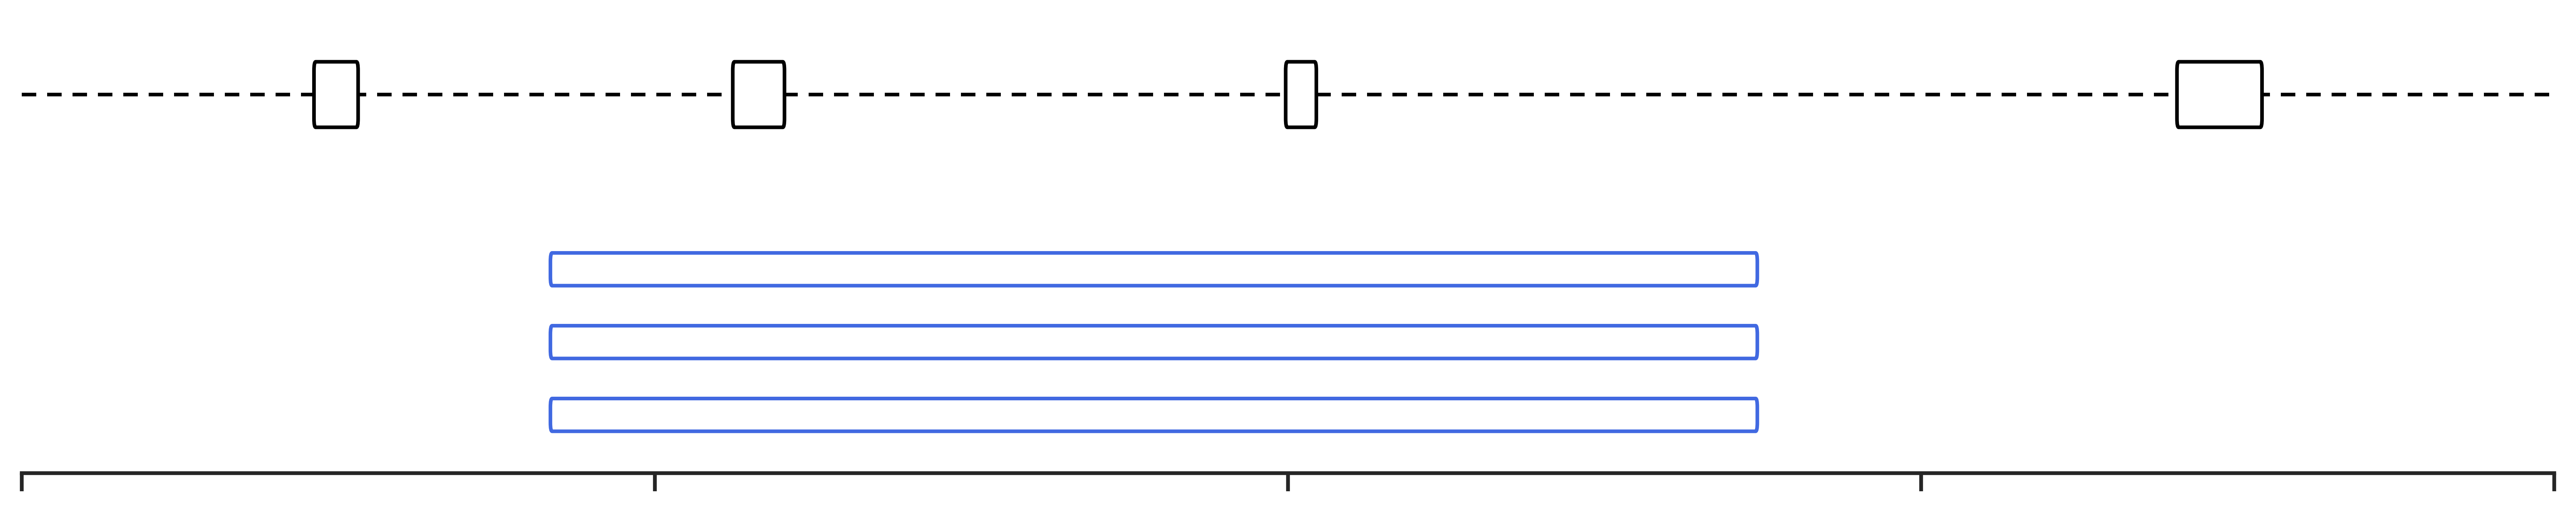

In [57]:
import gzip
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

sns.set_theme(style="ticks", context="notebook")

# ---------------- IDH1 ----------------
idh1_dels = [
    ("Patient 41", 208_242_803, 208_246_933),
    ("Patient 46", 208_242_803, 208_246_933),
    ("Patient 49", 208_242_803, 208_246_933),
]

# Minus strand, so the higher-coordinate exon has the LOWER exon number.
# I've labelled them Exon 6/7 on that basis — confirm the numbers against
# the exon_number field in your GTF before the figure goes anywhere.
exons = {
    "Exon 4": (208248369, 208248660),
    "Exon 5": (208245319, 208245424),
    "Exon 6": (208243427, 208243604),
    "Exon 7": (208241994, 208242145),
}
plot_gene_tracks(idh1_dels, exons=exons, bar_color='royalblue',
                 x_pad=1000, min_draw_bp=25, dpi=600, show_x_ticks=True,
                 hollow_bars=True,
                 savefig=None)  # e.g. savefig="idh1_dels_nolabels"
plt.show()